# AISHELL-1: exploratory and statistical analysis
Notebook supporting the *Data* and *Methodology* chapters of the thesis. Every number and figure below is computed from the dataset on disk. All parameters come from `config.json` (`eda` and `tones` sections). Figures are saved to `cfg["eda"]["fig_dir"]` so they can be included directly in the LaTeX report.

**Contents**
1. Setup
2. Dataset structure (splits, speakers)
3. Audio statistics (duration, sampling rate, loudness)
4. Transcript statistics (length, vocabulary, Zipf's law, coverage)
5. Tone statistics (distribution, bigrams, sandhi, χ² tests)
6. Speaking rate and its relation to utterance length
7. Acoustic features (log-mel statistics for normalisation)
8. F0 contours per tone (speaker-normalised, bootstrap CI, ANOVA)
9. Summary table for the thesis

## 1. Setup

In [1]:
import os, sys, glob, json, wave, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch, torchaudio
import librosa
from scipy import stats

# notebook lives in training/notebooks -> project root is two levels up
ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
sys.path.insert(0, ROOT)
os.chdir(ROOT)

from utils.config import cfg, resolve
from utils.tone_text import parse, find_cjk_font
from utils.f0 import f0_track, f0_range_auto, clean
from utils.syllables import segment
from scipy.signal import butter, sosfiltfilt

warnings.filterwarnings("ignore")
E, T = cfg["eda"], cfg["tones"]
rng = np.random.default_rng(E["seed"])
FIG_DIR = resolve(E["fig_dir"]); os.makedirs(FIG_DIR, exist_ok=True)
DATA = resolve(cfg["data_path"])

sns.set_theme(style="whitegrid", context="notebook")
cjk = find_cjk_font()
plt.rcParams["font.sans-serif"] = [cjk.get_name()] + plt.rcParams["font.sans-serif"]
plt.rcParams["axes.unicode_minus"] = False
tone_color = lambda k: T["colors"][str(k)]

def savefig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=E["fig_dpi"], bbox_inches="tight")
    return fig

## 2. Dataset structure

In [2]:
# transcript: "utt_id word word ..." (words are segmented by spaces; we join them into characters)
transcripts = {}
with open(os.path.join(DATA, cfg["transcript_file"]), encoding="utf-8") as f:
    for line in f:
        parts = line.split()
        if parts:
            transcripts[parts[0]] = "".join(parts[1:])

rows = []
wav_root = os.path.join(DATA, cfg["wav_dir"])
for path in glob.glob(os.path.join(wav_root, "**", "*.wav"), recursive=True):
    rel = os.path.relpath(path, wav_root).split(os.sep)
    utt = os.path.splitext(os.path.basename(path))[0]
    rows.append(dict(split=rel[0], speaker=rel[1], utt=utt, path=path, text=transcripts.get(utt)))
df = pd.DataFrame(rows)
df = df[df.text.notna()].reset_index(drop=True)
print(f"{len(df)} utterances with transcript, {len(transcripts)} transcripts in the file")
df.groupby("split").agg(utterances=("utt", "size"), speakers=("speaker", "nunique"))

16923 utterances with transcript, 141600 transcripts in the file


,utterances,speakers
split,,
train,16923,49


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
train,49.0,345.4,12.3,312.0,337.0,347.0,354.0,364.0


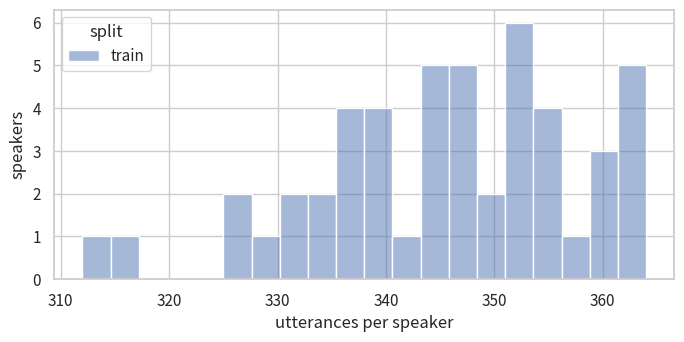

In [3]:
per_speaker = df.groupby(["split", "speaker"]).size().rename("n").reset_index()
display(per_speaker.groupby("split").n.describe().round(1))

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(data=per_speaker, x="n", hue="split", bins=20, ax=ax)
ax.set(xlabel="utterances per speaker", ylabel="speakers")
savefig(fig, "utterances_per_speaker");

## 3. Audio statistics

In [4]:
def wav_info(path):
    with wave.open(path) as w:   # header only, no decoding
        return w.getframerate(), w.getnchannels(), w.getnframes()

infos = [wav_info(p) for p in df.path]
df["sr"] = [i[0] for i in infos]
df["channels"] = [i[1] for i in infos]
df["dur"] = [i[2] / i[0] for i in infos]

print("sampling rates:", df.sr.value_counts().to_dict(), "| channels:", df.channels.value_counts().to_dict())
summary = df.groupby("split").dur.agg(["count", "sum", "mean", "std", "min", "median", "max"])
summary["sum"] = summary["sum"] / 3600
summary.rename(columns={"sum": "hours"}).round(2)

sampling rates: {16000: 16923} | channels: {1: 16923}


,count,hours,mean,std,min,median,max
split,,,,,,,
train,16923,21.19,4.51,1.44,1.34,4.22,12.54


duration quantiles [s]:
 0.01    2.31
0.05    2.75
0.50    4.22
0.95    7.23
0.99    8.94
log(duration) normality test: K2=197.3, p=1.41e-43; skewness=1.06


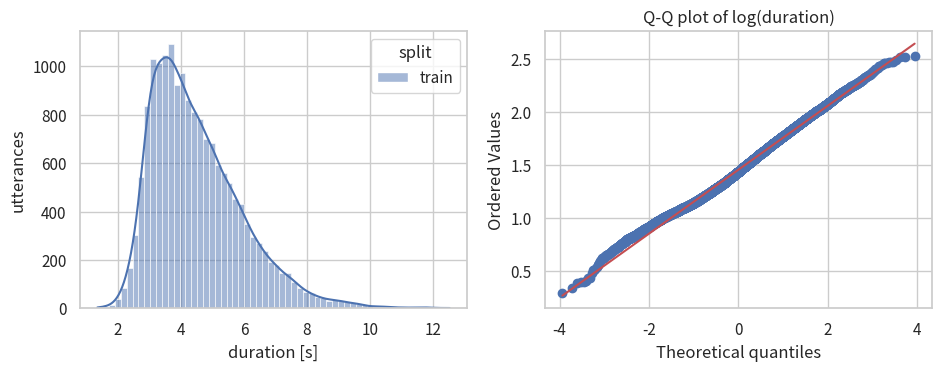

In [5]:
q = df.dur.quantile([.01, .05, .5, .95, .99]).round(2)
print("duration quantiles [s]:\n", q.to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(data=df, x="dur", hue="split", bins=60, kde=True, ax=axes[0])
axes[0].set(xlabel="duration [s]", ylabel="utterances")
stats.probplot(np.log(df.dur), dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot of log(duration)")
savefig(fig, "duration_distribution")

# normality of log-duration (D'Agostino-Pearson; large n -> compare against Q-Q plot, not only p)
k2, p = stats.normaltest(np.log(df.dur))
print(f"log(duration) normality test: K2={k2:.1f}, p={p:.3g}; skewness={stats.skew(df.dur):.2f}")

,rms_db,peak,silence,snr_proxy
count,300.000,300.000,300.000,300.000
mean,-32.840,0.209,0.254,27.916
std,4.665,0.136,0.100,7.060
min,-43.778,0.045,0.000,6.863
25%,-35.410,0.108,0.191,23.231
50%,-32.683,0.165,0.266,28.019
75%,-29.418,0.287,0.318,32.352
max,-22.654,0.786,0.515,45.837


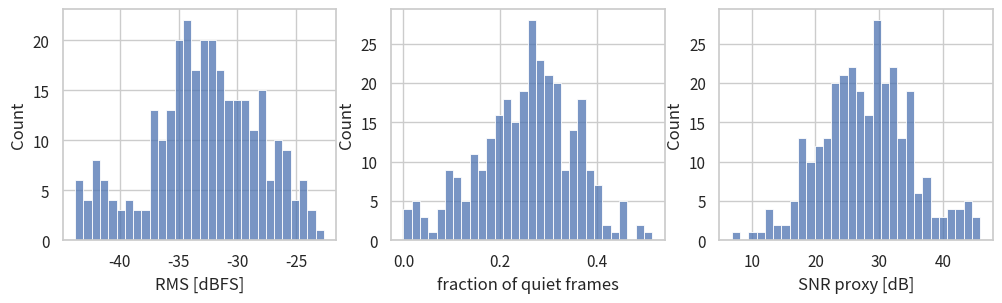

In [6]:
# loudness on a random sample (full corpus is slow)
sample = df.sample(min(E["mel_sample"], len(df)), random_state=E["seed"])
loud = []
for p in sample.path:
    y, sr = librosa.load(p, sr=None)
    rms = librosa.feature.rms(y=y)[0]
    loud.append(dict(rms_db=20 * np.log10(np.sqrt(np.mean(y**2)) + 1e-9),
                     peak=np.abs(y).max(),
                     silence=float(np.mean(rms < 0.1 * rms.max())),
                     snr_proxy=20 * np.log10(np.percentile(rms, 95) / (np.percentile(rms, 10) + 1e-9))))
loud = pd.DataFrame(loud)
display(loud.describe().round(3))
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, col, lab in zip(axes, ["rms_db", "silence", "snr_proxy"], ["RMS [dBFS]", "fraction of quiet frames", "SNR proxy [dB]"]):
    sns.histplot(loud[col], bins=30, ax=ax); ax.set_xlabel(lab)
savefig(fig, "loudness");

## 4. Transcript statistics

character types: 3174, tokens: 244187
         count  mean  std  min   25%   50%   75%   max
split                                                 
train  16923.0  14.4  4.4  2.0  11.0  14.0  18.0  33.0


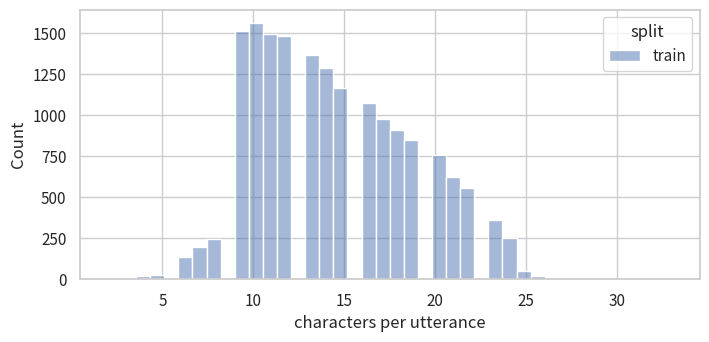

In [7]:
df["n_chars"] = df.text.str.len()
df["n_words"] = [len(l.split()) for l in
                 (" ".join(c) for c in df.text)]  # characters = syllables in Mandarin

char_counts = Counter("".join(df.text))
print(f"character types: {len(char_counts)}, tokens: {sum(char_counts.values())}")
print(df.groupby("split").n_chars.describe().round(1))

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(data=df, x="n_chars", hue="split", bins=40, ax=ax); ax.set(xlabel="characters per utterance")
savefig(fig, "chars_per_utterance");

Zipf exponent s = 1.77 (R^2 = 0.860)


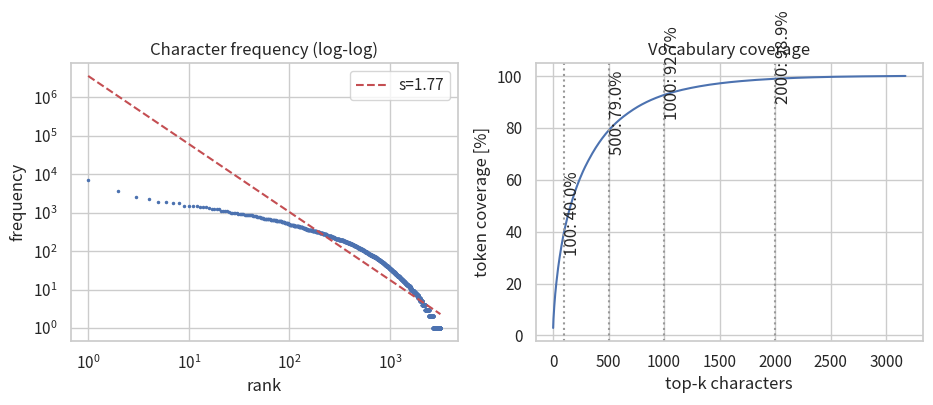

In [8]:
# Zipf's law: frequency ~ rank^-s
freq = np.array(sorted(char_counts.values(), reverse=True))
rank = np.arange(1, len(freq) + 1)
slope, intercept, r, *_ = stats.linregress(np.log(rank), np.log(freq))
print(f"Zipf exponent s = {-slope:.2f} (R^2 = {r**2:.3f})")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].loglog(rank, freq, ".", ms=3); axes[0].plot(rank, np.exp(intercept) * rank**slope, "r--", label=f"s={-slope:.2f}")
axes[0].set(xlabel="rank", ylabel="frequency", title="Character frequency (log-log)"); axes[0].legend()

cum = np.cumsum(freq) / freq.sum()
axes[1].plot(rank, cum * 100)
for k in E["top_k_coverage"]:
    if k <= len(cum):
        axes[1].axvline(k, ls=":", c=".6"); axes[1].text(k, cum[k-1]*100 - 8, f"{k}: {cum[k-1]*100:.1f}%", rotation=90)
axes[1].set(xlabel="top-k characters", ylabel="token coverage [%]", title="Vocabulary coverage")
savefig(fig, "zipf_coverage");

only one split on disk -> OOV analysis skipped
model vocabulary size: 1206


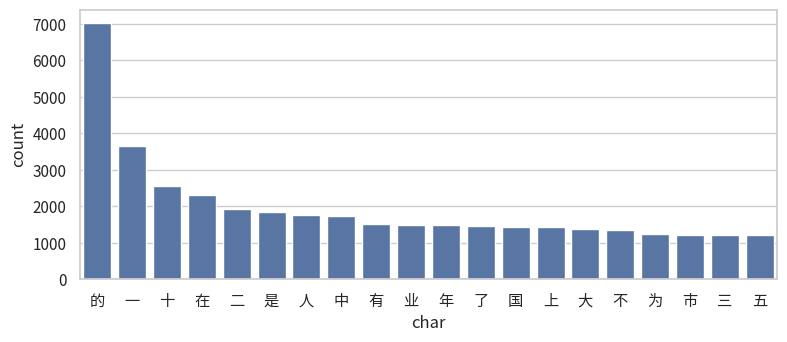

In [9]:
# most frequent characters
top = pd.DataFrame(char_counts.most_common(20), columns=["char", "count"])
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.barplot(data=top, x="char", y="count", color="C0", ax=ax)
savefig(fig, "top_chars")

# OOV rate between splits (needs more than one split)
splits = df.split.unique()
if len(splits) > 1:
    train_chars = set("".join(df[df.split == "train"].text))
    for s in splits:
        if s == "train": continue
        toks = "".join(df[df.split == s].text)
        print(f"{s}: OOV character rate vs train = {np.mean([c not in train_chars for c in toks])*100:.3f}%")
else:
    print("only one split on disk -> OOV analysis skipped")

# model vocabulary (pinyin+tone) vs. data
vocab = json.load(open(resolve(cfg["vocab_path"]), encoding="utf-8"))
print("model vocabulary size:", len(vocab))

## 5. Tone statistics

tone,1,2,3,4,5
split,,,,,
train,21.18,21.56,17.3,35.81,4.15


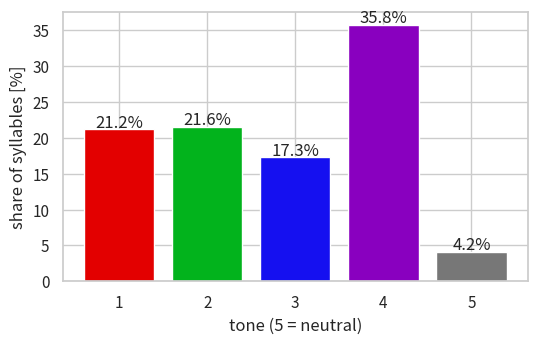

In [10]:
tone_rows = []
for utt, split, text in zip(df.utt, df.split, df.text):
    chars, syl, tones = parse(text)
    for i, (c, s, t) in enumerate(zip(chars, syl, tones)):
        tone_rows.append((utt, split, i, c, s, t))
tdf = pd.DataFrame(tone_rows, columns=["utt", "split", "pos", "char", "syl", "tone"])

dist = tdf.groupby("split").tone.value_counts(normalize=True).unstack().mul(100).round(2)
display(dist)

fig, ax = plt.subplots(figsize=(6, 3.5))
share = tdf.tone.value_counts(normalize=True).sort_index() * 100
ax.bar(share.index, share.values, color=[tone_color(k) for k in share.index])
for k, v in share.items(): ax.text(k, v + .3, f"{v:.1f}%", ha="center")
ax.set(xlabel="tone (5 = neutral)", ylabel="share of syllables [%]")
savefig(fig, "tone_distribution");

tone bigram independence: chi2=800, dof=16, p=6.12e-160, Cramer's V=0.030


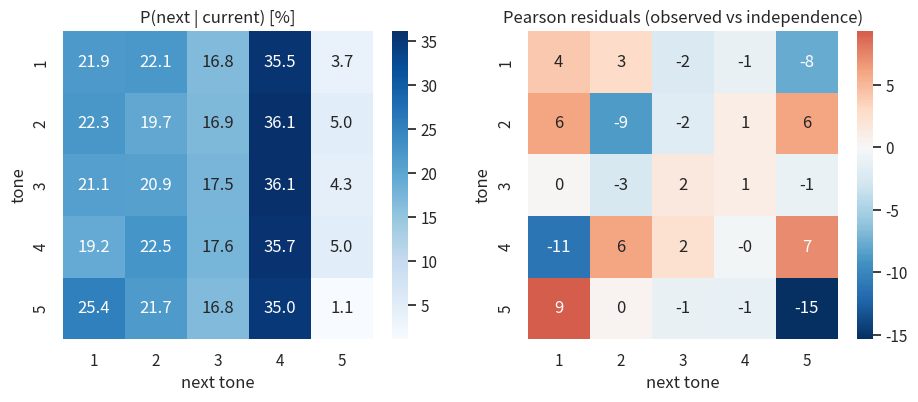

In [11]:
# tone bigrams within an utterance
nxt = tdf.groupby("utt").tone.shift(-1)
big = pd.crosstab(tdf.tone, nxt.reindex(tdf.index).dropna().astype(int))
chi2, p, dof, expected = stats.chi2_contingency(big)
cramers_v = np.sqrt(chi2 / (big.values.sum() * (min(big.shape) - 1)))
print(f"tone bigram independence: chi2={chi2:.0f}, dof={dof}, p={p:.3g}, Cramer's V={cramers_v:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(big.div(big.sum(1), axis=0) * 100, annot=True, fmt=".1f", cmap="Blues", ax=axes[0])
axes[0].set(xlabel="next tone", ylabel="tone", title="P(next | current) [%]")
sns.heatmap((big - expected) / np.sqrt(expected), annot=True, fmt=".0f", cmap="RdBu_r", center=0, ax=axes[1])
axes[1].set(xlabel="next tone", ylabel="tone", title="Pearson residuals (observed vs independence)")
savefig(fig, "tone_bigrams");

In [12]:
# third-tone sandhi candidates: T3 T3 (the first one is realised as T2 in speech)
pairs = pd.DataFrame({"a": tdf.tone, "b": nxt}).dropna()
sandhi_share = ((pairs.a == 3) & (pairs.b == 3)).mean() * 100
print(f"T3-T3 bigrams: {sandhi_share:.2f}% of all bigrams -> the 'nominal' tone labels disagree with the surface tone there")

# polyphones: characters with more than one reading in the corpus
readings = tdf.groupby("char").syl.nunique()
print(f"characters with >1 pinyin reading assigned by pypinyin: {(readings > 1).sum()} of {len(readings)}")

# train vs other splits: is the tone distribution the same?
if tdf.split.nunique() > 1:
    ct = pd.crosstab(tdf.split, tdf.tone)
    chi2, p, *_ = stats.chi2_contingency(ct)
    print(f"tone distribution differs between splits? chi2={chi2:.1f}, p={p:.3g}")

T3-T3 bigrams: 3.06% of all bigrams -> the 'nominal' tone labels disagree with the surface tone there
characters with >1 pinyin reading assigned by pypinyin: 60 of 3174


## 6. Speaking rate
Speaking rate [syllables/s] is computed as characters divided by duration. Because Mandarin characters are monosyllabic, this is a proxy for the true syllable rate.

         count  mean   std   min   25%   50%   75%   max
split                                                   
train  16923.0  3.24  0.51  1.29  2.91  3.23  3.57  5.05
Spearman(duration, #chars) = 0.876 (p=0)
Kruskal-Wallis across 49 speakers: H=6993, p=0, epsilon^2=0.412


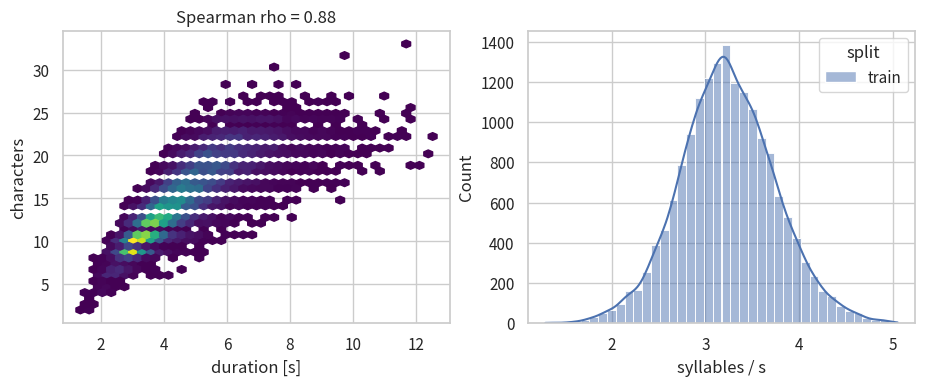

In [13]:
df["rate"] = df.n_chars / df.dur
print(df.groupby("split").rate.describe().round(2))

rho, p = stats.spearmanr(df.dur, df.n_chars)
print(f"Spearman(duration, #chars) = {rho:.3f} (p={p:.2g})")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hexbin(df.dur, df.n_chars, gridsize=40, cmap="viridis", mincnt=1)
axes[0].set(xlabel="duration [s]", ylabel="characters", title=f"Spearman rho = {rho:.2f}")
sns.histplot(data=df, x="rate", hue="split", bins=40, kde=True, ax=axes[1]); axes[1].set(xlabel="syllables / s")
savefig(fig, "speaking_rate")

# per-speaker variability: ANOVA / Kruskal on speaker (is rate speaker-dependent?)
groups = [g.rate.values for _, g in df.groupby("speaker") if len(g) > 5]
h, p = stats.kruskal(*groups)
eta = (h - len(groups) + 1) / (len(df) - len(groups))
print(f"Kruskal-Wallis across {len(groups)} speakers: H={h:.0f}, p={p:.3g}, epsilon^2={eta:.3f}")

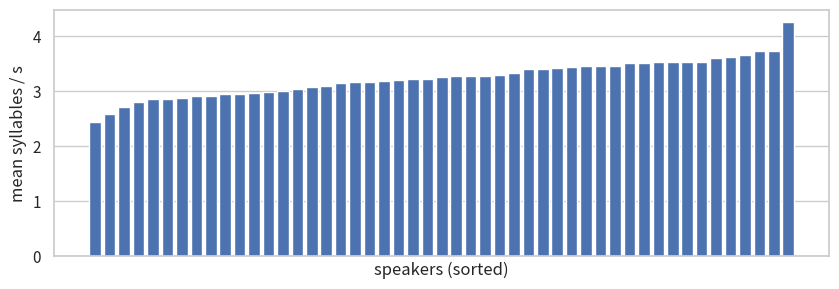

In [14]:
if df.split.nunique() > 1:
    a, b = [g.rate.values for _, g in df.groupby("split")][:2]
    u, p = stats.mannwhitneyu(a, b); print(f"Mann-Whitney between first two splits: U={u:.0f}, p={p:.3g}")
sp = df.groupby("speaker").rate.mean().sort_values()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(range(len(sp)), sp.values); ax.set(xticks=[], xlabel="speakers (sorted)", ylabel="mean syllables / s")
savefig(fig, "speaker_rate");

## 7. Acoustic features (log-mel statistics)

log-mel: global mean=-6.99, std=4.23, frames=135286
frame count per utterance:  {'count': 300.0, 'mean': 451.0, 'std': 143.6, 'min': 141.0, '25%': 343.8, '50%': 426.0, '75%': 539.8, 'max': 1052.0}


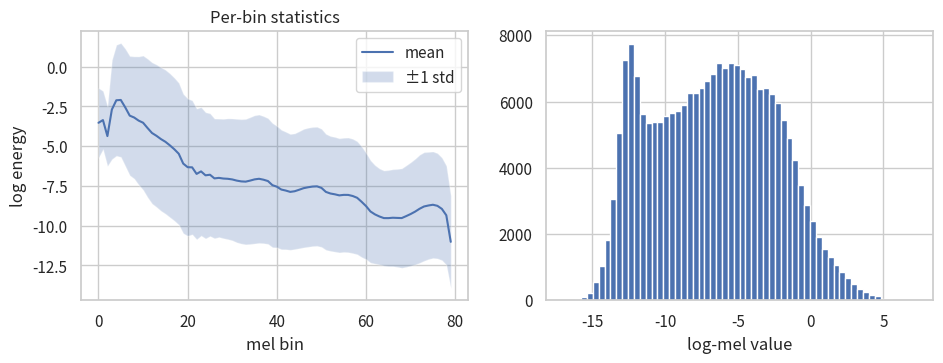

In [15]:
# same front-end as AishellDataset (log-mel, hop in ms); audio is loaded with librosa so the
# notebook does not depend on the torchaudio/ffmpeg backend
sr = cfg["sample_rate"]
mel_tf = torchaudio.transforms.MelSpectrogram(sample_rate=sr, n_mels=cfg["n_mels"], n_fft=cfg["n_fft"],
                                              hop_length=int(sr * cfg["hop_ms"] / 1000))
pick = df.sample(min(E["mel_sample"], len(df)), random_state=E["seed"])
mels = []
for p in pick.path:
    y = torch.from_numpy(librosa.load(p, sr=sr)[0])
    mels.append(torch.log(mel_tf(y) + cfg["log_eps"]).T)   # (time, n_mels)
allm = torch.cat(mels)                    # (frames, n_mels)
mu, sd = allm.mean(0), allm.std(0)
print(f"log-mel: global mean={allm.mean():.2f}, std={allm.std():.2f}, frames={len(allm)}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(mu, label="mean"); axes[0].fill_between(range(len(mu)), mu - sd, mu + sd, alpha=.25, label="±1 std")
axes[0].set(xlabel="mel bin", ylabel="log energy", title="Per-bin statistics"); axes[0].legend()
vals = allm.flatten()[::50].double().numpy()
vals = vals[np.isfinite(vals)]
edges = np.linspace(vals.min(), vals.max(), 61)
counts = np.bincount(np.clip(np.searchsorted(edges, vals, side="right") - 1, 0, 59), minlength=60)  # manual binning
axes[1].bar(edges[:-1], counts, width=np.diff(edges), align="edge"); axes[1].set(xlabel="log-mel value")
savefig(fig, "mel_statistics")
print("frame count per utterance: ", pd.Series([len(m) for m in mels]).describe().round(1).to_dict())

## 8. F0 contours per tone
Pipeline: high-pass → pYIN → cleaning → syllable segmentation (energy + Viterbi) → one contour per syllable. F0 is converted to semitones relative to each speaker's median, which removes the speaker's pitch range (cf. Nature Communications 2021, doi:10.1038/s41467-021-21430-x). Each contour is resampled to `contour_points` points.

In [16]:
cache = resolve("temp/eda_contours.parquet")
sr = cfg["sample_rate"]

def utterance_contours(path, text):
    y_raw = librosa.load(path, sr=sr)[0]
    y = sosfiltfilt(butter(T["highpass_order"], T["highpass_hz"], "highpass", fs=sr, output="sos"), y_raw)
    chars, syl, tones = parse(text)
    fmin, fmax = f0_range_auto(y, sr, T["gate"])
    t, f0 = f0_track(y, sr, fmin, fmax, T["gate"])
    f0 = clean(f0, fmin, fmax)
    bounds = segment(y, sr, len(chars), ~np.isnan(f0), t, 0.0)
    out = []
    for (a, b), c, tone in zip(bounds, chars, tones):
        m = (t >= a) & (t <= b)
        seg_t, seg_f = t[m], f0[m]
        ok = ~np.isnan(seg_f)
        if ok.sum() < 5: continue
        grid = np.linspace(seg_t[ok][0], seg_t[ok][-1], E["contour_points"])
        out.append(dict(char=c, tone=tone, dur=b - a, hz=np.interp(grid, seg_t[ok], seg_f[ok])))
    return out

if os.path.exists(cache):
    cdf = pd.read_parquet(cache)
else:
    recs = []
    pick = df.sample(min(E["f0_utterances"], len(df)), random_state=E["seed"])
    for path, text, spk in zip(pick.path, pick.text, pick.speaker):
        try:
            for r in utterance_contours(path, text):
                r["speaker"] = spk; recs.append(r)
        except Exception as e:
            print("skip", os.path.basename(path), e)
    cdf = pd.DataFrame(recs)
    os.makedirs(os.path.dirname(cache), exist_ok=True)
    cdf.assign(hz=cdf.hz.map(list)).to_parquet(cache)
cdf["hz"] = cdf.hz.map(np.asarray)
print(len(cdf), "syllable contours;", cdf.speaker.nunique(), "speakers")
cdf.tone.value_counts().sort_index()

1479 syllable contours; 47 speakers


tone
1    328
2    336
3    238
4    523
5     54
Name: count, dtype: int64

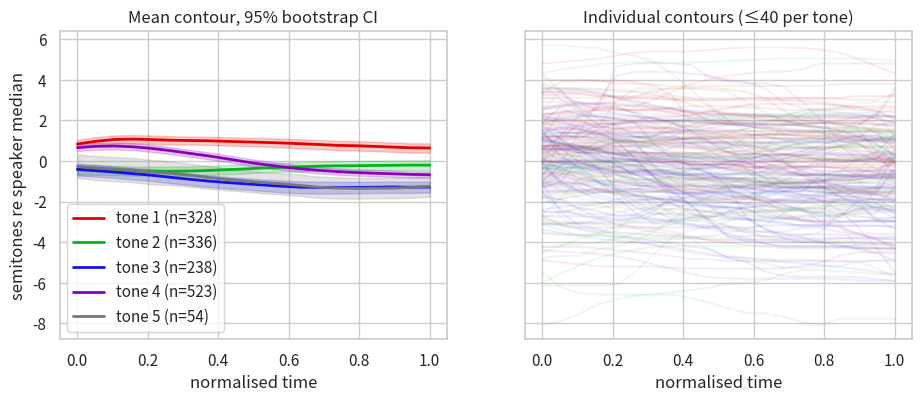

In [17]:
# speaker normalisation: semitones relative to the speaker's median f0
spk_med = cdf.groupby("speaker").hz.apply(lambda s: np.median(np.concatenate(s.values)))
cdf["st"] = [12 * np.log2(h / spk_med[s]) for h, s in zip(cdf.hz, cdf.speaker)]

x = np.linspace(0, 1, E["contour_points"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for k in range(1, 6):
    arr = np.stack(cdf[cdf.tone == k].st.values)
    if len(arr) < 3: continue
    mean = arr.mean(0)
    # bootstrap CI of the mean contour
    boots = np.stack([arr[rng.integers(0, len(arr), len(arr))].mean(0) for _ in range(E["bootstrap"])])
    lo, hi = np.percentile(boots, [100 * E["alpha"] / 2, 100 * (1 - E["alpha"] / 2)], axis=0)
    axes[0].plot(x, mean, color=tone_color(k), lw=2, label=f"tone {k} (n={len(arr)})")
    axes[0].fill_between(x, lo, hi, color=tone_color(k), alpha=.2)
    axes[1].plot(x, arr.T[:, :40], color=tone_color(k), alpha=.08)
axes[0].set(xlabel="normalised time", ylabel="semitones re speaker median", title="Mean contour, 95% bootstrap CI"); axes[0].legend()
axes[1].set(xlabel="normalised time", title="Individual contours (≤40 per tone)")
savefig(fig, "tone_contours");

In [18]:
# features describing the contour shape and tests between tones
def shape(st):
    return dict(mean=st.mean(), slope=np.polyfit(x, st, 1)[0], rng=st.max() - st.min(),
                curv=np.polyfit(x, st, 2)[0], end_minus_start=st[-3:].mean() - st[:3].mean())

feat = pd.DataFrame([shape(s) for s in cdf.st]); feat["tone"] = cdf.tone.values; feat["dur"] = cdf.dur.values
display(feat.groupby("tone").agg(["mean", "std"]).round(2))

for col in ["mean", "slope", "curv", "dur"]:
    groups = [g[col].values for _, g in feat.groupby("tone") if len(g) > 3]
    h, p = stats.kruskal(*groups)
    print(f"{col:>6}: Kruskal-Wallis H={h:.1f}, p={p:.3g}")

mean       slope         rng        curv       end_minus_start        \
      mean   std  mean   std  mean   std  mean   std            mean   std   
tone                                                                         
1     0.88  1.89 -0.39  1.95  1.76  1.48 -0.66  3.76           -0.30  1.76   
2    -0.36  2.01  0.34  2.29  1.97  1.49  0.24  3.98            0.24  1.92   
3    -1.02  2.09 -0.95  2.31  2.18  1.52  1.30  4.34           -0.81  1.95   
4    -0.01  1.82 -1.70  2.15  2.32  1.49  0.44  4.04           -1.36  1.80   
5    -0.93  1.83 -1.18  2.28  2.28  1.51  1.04  4.39           -0.96  1.97   

       dur        
      mean   std  
tone              
1     0.25  0.10  
2     0.25  0.10  
3     0.26  0.12  
4     0.26  0.10  
5     0.22  0.07

  mean: Kruskal-Wallis H=161.0, p=8.84e-34
 slope: Kruskal-Wallis H=215.4, p=1.82e-45
  curv: Kruskal-Wallis H=43.0, p=1.02e-08
   dur: Kruskal-Wallis H=7.1, p=0.13


In [19]:
# pairwise Mann-Whitney with Holm correction on mean slope
from itertools import combinations
tones_present = sorted(feat.tone.unique())
res = []
for a, b in combinations(tones_present, 2):
    u, p = stats.mannwhitneyu(feat[feat.tone == a].slope, feat[feat.tone == b].slope)
    res.append((a, b, p))
res = pd.DataFrame(res, columns=["tone_a", "tone_b", "p"]).sort_values("p")
m = len(res); res["p_holm"] = np.minimum(1, np.maximum.accumulate(res.p.values * (m - np.arange(m))))
res["significant"] = res.p_holm < E["alpha"]
res.round(4)

,tone_a,tone_b,p,p_holm,significant
5,2,4,0.0000,0.0000,True
2,1,4,0.0000,0.0000,True
4,2,3,0.0000,0.0000,True
7,3,4,0.0000,0.0000,True
0,1,2,0.0000,0.0000,True
6,2,5,0.0000,0.0000,True
1,1,3,0.0002,0.0009,True
3,1,5,0.0097,0.0290,True
9,4,5,0.0451,0.0901,False
8,3,5,0.6078,0.6078,False


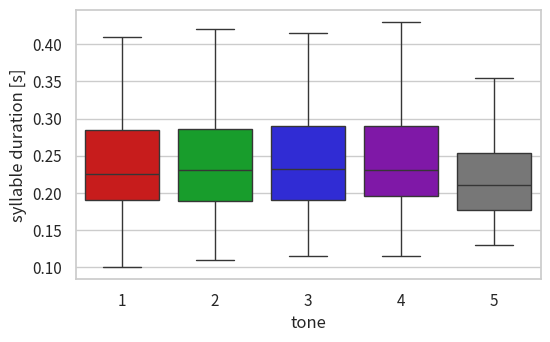

In [20]:
# mean duration per tone (neutral tone is expected to be shortest)
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.boxplot(data=feat, x="tone", y="dur", palette=[tone_color(k) for k in tones_present], ax=ax, showfliers=False)
ax.set(xlabel="tone", ylabel="syllable duration [s]")
savefig(fig, "tone_duration");

## 9. Summary table for the thesis

In [21]:
summary_tbl = pd.Series({
    "utterances": len(df), "speakers": df.speaker.nunique(), "hours": round(df.dur.sum() / 3600, 2),
    "sampling rate [Hz]": int(df.sr.mode()[0]), "mean duration [s]": round(df.dur.mean(), 2),
    "mean chars / utterance": round(df.n_chars.mean(), 1), "character types": len(char_counts),
    "Zipf exponent": round(-slope, 2), "mean speaking rate [syll/s]": round(df.rate.mean(), 2),
    "T3-T3 bigrams [%]": round(sandhi_share, 2),
    "log-mel mean / std": f"{allm.mean():.2f} / {allm.std():.2f}",
})
display(summary_tbl.to_frame("value"))
summary_tbl.to_frame("value").to_latex(os.path.join(FIG_DIR, "dataset_summary.tex"))
print("figures saved in", FIG_DIR)

,value
utterances,16923
speakers,49
hours,21.19
sampling rate [Hz],16000
mean duration [s],4.51
mean chars / utterance,14.4
character types,3174
Zipf exponent,1.77
mean speaking rate [syll/s],3.24
T3-T3 bigrams [%],3.06


figures saved in /home/szczuru/si-tone/report/gfx/eda
